<a href="https://colab.research.google.com/github/akshayamithra12-ship-it/AI-Powered-Virtual-Finance-Assistant/blob/main/hazardous_asteroid_prediction_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛰️ Project Sentinel: Hazardous Asteroid Prediction AI

**Task:** Supervised binary classification — predict whether a Near-Earth Object (NEO) is **Hazardous** or **Non-Hazardous** from its physical and approach characteristics.

| Phase | Content |
|---|---|
| 1 | Data preparation & preprocessing |
| 2 | Exploratory data analysis |
| 3 | Feature engineering & selection |
| 4 | Model development (split, imbalance handling, tuning, comparison) |
| 5 | Explainability & visualization |
| 6 | Deployment (saved model + Gradio user interface) |

**How to run:** upload the dataset CSV (`neo.csv`) next to this notebook (in Colab: left sidebar → Files → upload, or run the notebook and use the upload prompt in Phase 1), then **Runtime → Run all**.

In [1]:
# Install extra libraries (already present on most setups; quiet if so)
%pip install -q shap gradio imbalanced-learn

In [2]:
import os, glob, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
SEED = 42
np.random.seed(SEED)

## Phase 1 — Data Preparation & Preprocessing
### 1.1 Load the NASA NEO dataset

In [3]:
candidates = sorted(glob.glob("neo*.csv") + glob.glob("/content/neo*.csv") + glob.glob("/content/drive/MyDrive/neo*.csv"))
if not candidates:
    try:                                   # Google Colab upload prompt
        from google.colab import files
        up = files.upload()
        candidates = list(up.keys())
    except ImportError:
        raise FileNotFoundError("Place the NEO dataset (e.g. neo.csv) in the same folder as this notebook.")
DATA_PATH = candidates[0]
raw = pd.read_csv(DATA_PATH)
print(f"Loaded '{DATA_PATH}'  ->  {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded '/content/neo (3).csv'  ->  90,836 rows x 10 columns


,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


### 1.2 First look: types, missing values, duplicates, cardinality

In [4]:
raw.info()
print("\nMissing values:\n", raw.isna().sum().to_string())
print("\nExact duplicate rows:", raw.duplicated().sum())
print("\nUnique values per column:\n", raw.nunique().to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  object 
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  object 
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), object(2)
memory usage: 5.7+ MB

Missing values:
 id                    0
name                  0
est_diameter_min      0
est_diameter_max      0
relative_velocity     0
miss_distance         0
orbiting_body         0
sentry_object         0
absolute_magnitude    

**Key observations**
- There are **no missing values**, but the pipeline below still contains an imputer so it stays robust on new data.
- `orbiting_body` (always *Earth*) and `sentry_object` (always *False*) are **constant** → no predictive information.
- The table has ~90k rows but only ~27k unique asteroid `id`s: **the same asteroid appears in several rows (one per close approach)**. Its size / absolute magnitude and its hazard label are identical in every row. This matters for how we split the data later (Phase 4) — otherwise the same asteroid ends up in both train and test and the score is inflated.
- The brief mentions "orbital parameters"; in this dataset the orbital information is limited to the approach geometry (`relative_velocity`, `miss_distance`) plus the number of recorded approaches per asteroid, which we derive in Phase 3.

### 1.3 Clean: handle missing values, remove unnecessary attributes, encode variables

In [5]:
df = raw.copy()

# (a) duplicates
df = df.drop_duplicates()

# (b) missing values -> report; numeric columns are imputed with the median *inside the model pipelines*
#     (so no information from the test set leaks into the imputer). Rows with a missing target are removed.
df = df.dropna(subset=["hazardous"])

# (c) remove unnecessary attributes
#     - 'name' : free-text identifier              - 'orbiting_body', 'sentry_object': constant columns
const_cols = [c for c in df.columns if df[c].nunique() <= 1]
drop_cols = ["name"] + const_cols
print("Dropping:", drop_cols)
df = df.drop(columns=drop_cols)
#     'id' is NOT a feature, but we keep it as the *group key* (one asteroid = one group) for leakage-free splitting.

# (d) encode categorical / boolean variables
df["hazardous"] = df["hazardous"].astype(int)                       # target: True/False -> 1/0
cat_cols = [c for c in df.select_dtypes(include=["object", "category", "string"]).columns]
if cat_cols:
    df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Categorical columns encoded:", cat_cols or "none remaining")

# (e) sanity filter: physically impossible values
num_raw = ["est_diameter_min", "est_diameter_max", "relative_velocity", "miss_distance"]
df = df[(df[num_raw] > 0).all(axis=1)].reset_index(drop=True)
print("\nClean shape:", df.shape)
df.head()

Dropping: ['name', 'orbiting_body', 'sentry_object']
Categorical columns encoded: none remaining

Clean shape: (90836, 7)


,id,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,2162635,1.198271,2.679415,13569.249224,5.483974e+07,16.73,0
1,2277475,0.265800,0.594347,73588.726663,6.143813e+07,20.00,1
2,2512244,0.722030,1.614507,114258.692129,4.979872e+07,17.83,0
3,3596030,0.096506,0.215794,24764.303138,2.543497e+07,22.20,0
4,3667127,0.255009,0.570217,42737.733765,4.627557e+07,20.09,1


### 1.4 Normalisation / scaling
Different features live on wildly different scales (`miss_distance` ~ 10⁷ km, `absolute_magnitude` ~ 20). Distance-/gradient-based models (Logistic Regression) need scaling, while tree-based models (Random Forest, Gradient Boosting) do not. We therefore apply a `StandardScaler` **inside the model pipelines** (fit on training folds only → no leakage) and use log transforms for the heavy-tailed variables in Phase 3.

## Phase 2 — Exploratory Data Analysis

### 2.1 Class distribution

               count  percent
hazardous                    
Non-Hazardous  81996    90.27
Hazardous       8840     9.73


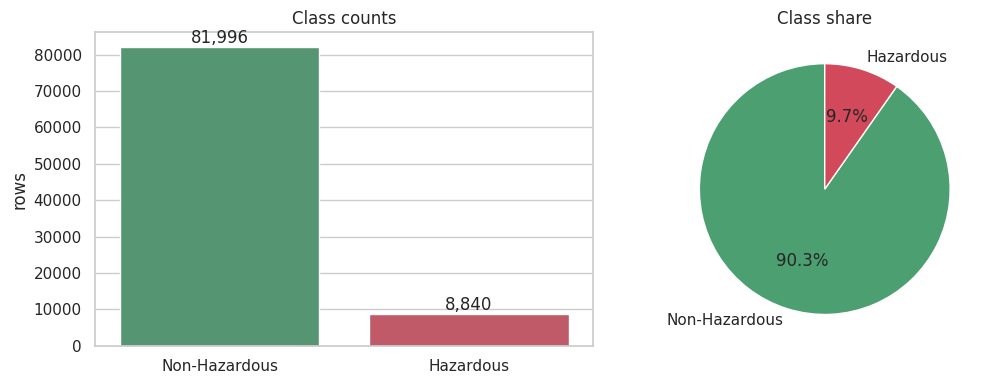


Naive 'always Non-Hazardous' model -> accuracy = 0.903, hazard recall = 0.000


In [6]:
cnt = df["hazardous"].value_counts().sort_index()
pct = df["hazardous"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": cnt, "percent": pct.round(2)}).rename(index={0: "Non-Hazardous", 1: "Hazardous"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=["Non-Hazardous", "Hazardous"], y=cnt.values, palette=["#4C9F70", "#D1495B"], ax=ax[0])
ax[0].set_title("Class counts"); ax[0].set_ylabel("rows")
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].pie(cnt.values, labels=["Non-Hazardous", "Hazardous"], colors=["#4C9F70", "#D1495B"], autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

naive = DummyClassifier(strategy="most_frequent").fit(df[["absolute_magnitude"]], df["hazardous"])
p = naive.predict(df[["absolute_magnitude"]])
print(f"\nNaive 'always Non-Hazardous' model -> accuracy = {accuracy_score(df['hazardous'], p):.3f}, "
      f"hazard recall = {recall_score(df['hazardous'], p):.3f}")

⚠️ **Class imbalance:** a model that never flags a hazard still scores ~90 % accuracy but has **0 % recall** on the objects that matter. Accuracy is therefore *not* used to judge models; we use Recall, Precision, F1, PR-AUC, ROC-AUC and MCC, and handle the imbalance explicitly in Phase 4.

### 2.2 Summary statistics (overall and by class)

In [7]:
eda_cols = ["absolute_magnitude", "est_diameter_min", "est_diameter_max", "relative_velocity", "miss_distance"]
display(df[eda_cols].describe().T.round(3))
display(df.groupby("hazardous")[eda_cols].median().rename(index={0: "Non-Hazardous (median)", 1: "Hazardous (median)"}).T.round(3))
print("Skewness:\n", df[eda_cols].skew().round(2).to_string())

,count,mean,std,min,25%,50%,75%,max
absolute_magnitude,90836.0,2.352700e+01,2.894000e+00,9.230,2.134000e+01,2.370000e+01,2.570000e+01,3.320000e+01
est_diameter_min,90836.0,1.270000e-01,2.990000e-01,0.001,1.900000e-02,4.800000e-02,1.430000e-01,3.789300e+01
est_diameter_max,90836.0,2.850000e-01,6.670000e-01,0.001,4.300000e-02,1.080000e-01,3.210000e-01,8.473100e+01
relative_velocity,90836.0,4.806692e+04,2.529330e+04,203.346,2.861902e+04,4.419012e+04,6.292361e+04,2.369901e+05
miss_distance,90836.0,3.706655e+07,2.235204e+07,6745.533,1.721082e+07,3.784658e+07,5.654900e+07,7.479865e+07


hazardous,Non-Hazardous (median),Hazardous (median)
absolute_magnitude,2.410000e+01,2.060000e+01
est_diameter_min,4.000000e-02,2.020000e-01
est_diameter_max,9.000000e-02,4.510000e-01
relative_velocity,4.256550e+04,5.865801e+04
miss_distance,3.748745e+07,4.098372e+07


Skewness:
 absolute_magnitude    -0.14
est_diameter_min      41.14
est_diameter_max      41.14
relative_velocity      0.91
miss_distance         -0.04


### 2.3 Distributions by class

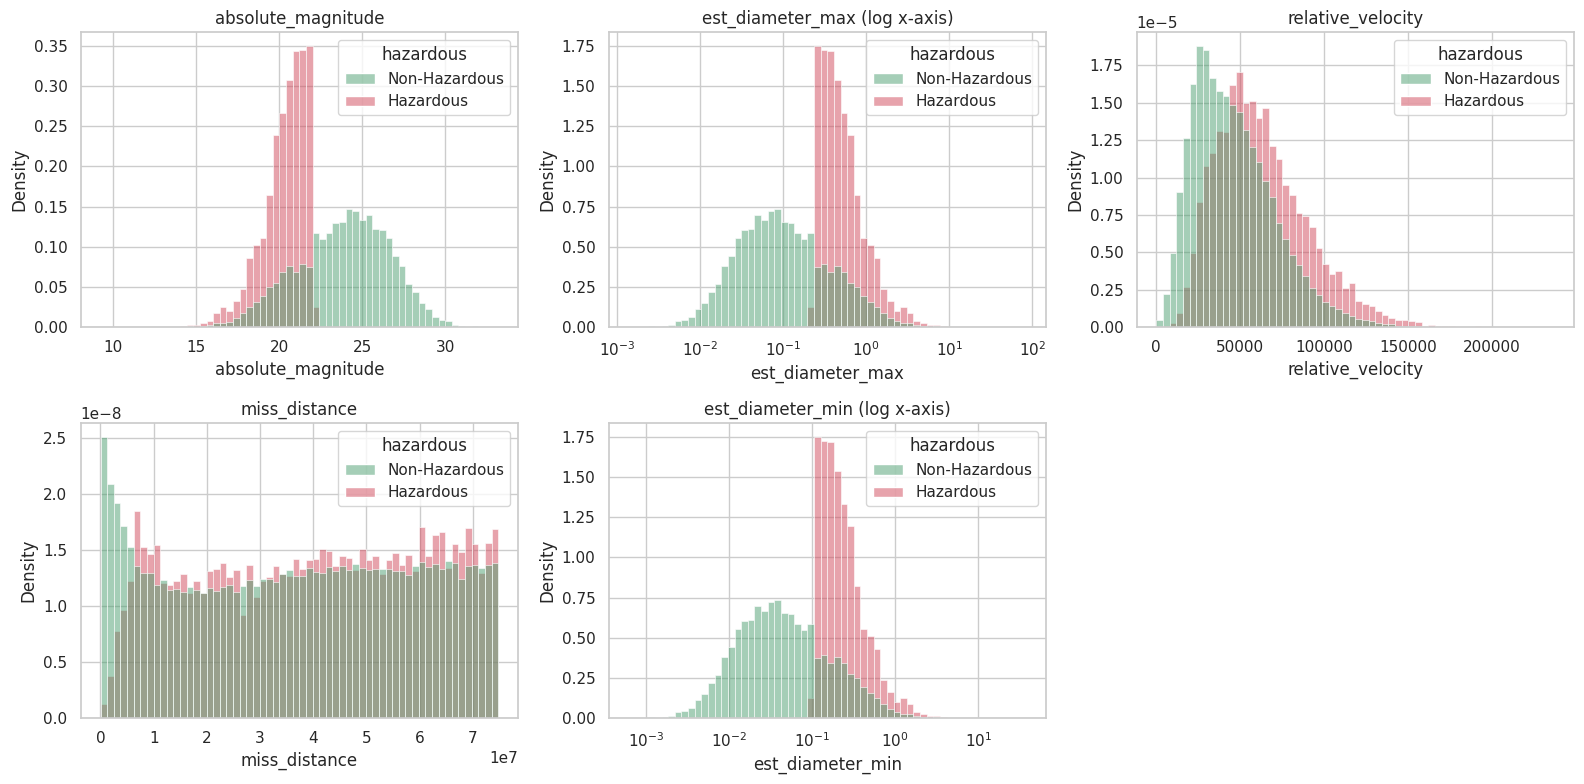

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
specs = [("absolute_magnitude", False), ("est_diameter_max", True), ("relative_velocity", False),
         ("miss_distance", False), ("est_diameter_min", True)]
for ax, (col, logx) in zip(axes.ravel(), specs):
    sns.histplot(data=df, x=col, hue=df["hazardous"].map({0: "Non-Hazardous", 1: "Hazardous"}), bins=60,
                 stat="density", common_norm=False, log_scale=logx, palette=["#4C9F70", "#D1495B"], alpha=0.5, ax=ax)
    ax.set_title(col + (" (log x-axis)" if logx else ""))
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 2.4 Relationships between important features

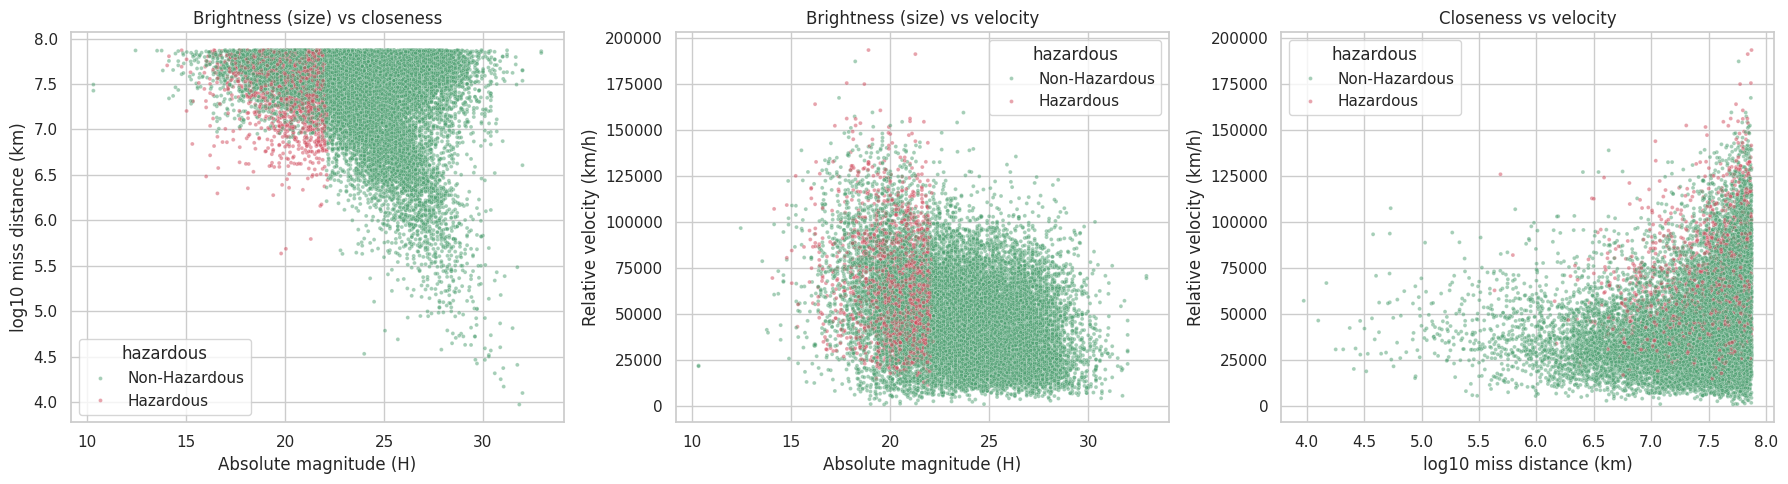

In [9]:
sample = df.sample(20000, random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
lab = sample["hazardous"].map({0: "Non-Hazardous", 1: "Hazardous"})
pal = {"Non-Hazardous": "#4C9F70", "Hazardous": "#D1495B"}
sns.scatterplot(x=sample["absolute_magnitude"], y=np.log10(sample["miss_distance"]), hue=lab, palette=pal, s=8, alpha=.5, ax=axes[0])
axes[0].set(xlabel="Absolute magnitude (H)", ylabel="log10 miss distance (km)", title="Brightness (size) vs closeness")
sns.scatterplot(x=sample["absolute_magnitude"], y=sample["relative_velocity"], hue=lab, palette=pal, s=8, alpha=.5, ax=axes[1])
axes[1].set(xlabel="Absolute magnitude (H)", ylabel="Relative velocity (km/h)", title="Brightness (size) vs velocity")
sns.scatterplot(x=np.log10(sample["miss_distance"]), y=sample["relative_velocity"], hue=lab, palette=pal, s=8, alpha=.5, ax=axes[2])
axes[2].set(xlabel="log10 miss distance (km)", ylabel="Relative velocity (km/h)", title="Closeness vs velocity")
plt.tight_layout(); plt.show()

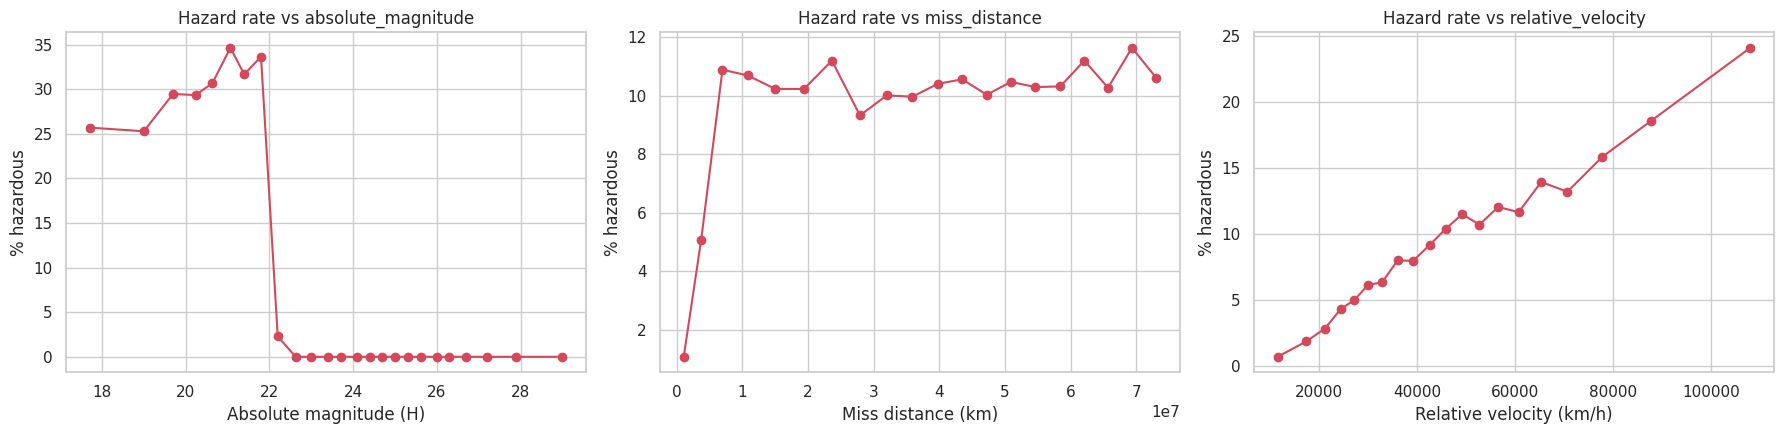

Largest absolute magnitude among hazardous objects: 22.4
Share of hazardous objects with H <= 22: 100.0 %


In [10]:
# Hazard rate as a function of absolute magnitude, miss distance, velocity (binned)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (col, bins, xl) in zip(axes, [("absolute_magnitude", 25, "Absolute magnitude (H)"),
                                       ("miss_distance", 20, "Miss distance (km)"),
                                       ("relative_velocity", 20, "Relative velocity (km/h)")]):
    b = pd.qcut(df[col], bins, duplicates="drop")
    rate = df.groupby(b, observed=True)["hazardous"].mean() * 100
    mid = df.groupby(b, observed=True)[col].median()
    ax.plot(mid.values, rate.values, marker="o", color="#D1495B")
    ax.set(xlabel=xl, ylabel="% hazardous", title=f"Hazard rate vs {col}")
plt.tight_layout(); plt.show()

print("Largest absolute magnitude among hazardous objects:", df.loc[df.hazardous == 1, "absolute_magnitude"].max())
print("Share of hazardous objects with H <= 22:", round((df.loc[df.hazardous == 1, "absolute_magnitude"] <= 22.5).mean() * 100, 1), "%")

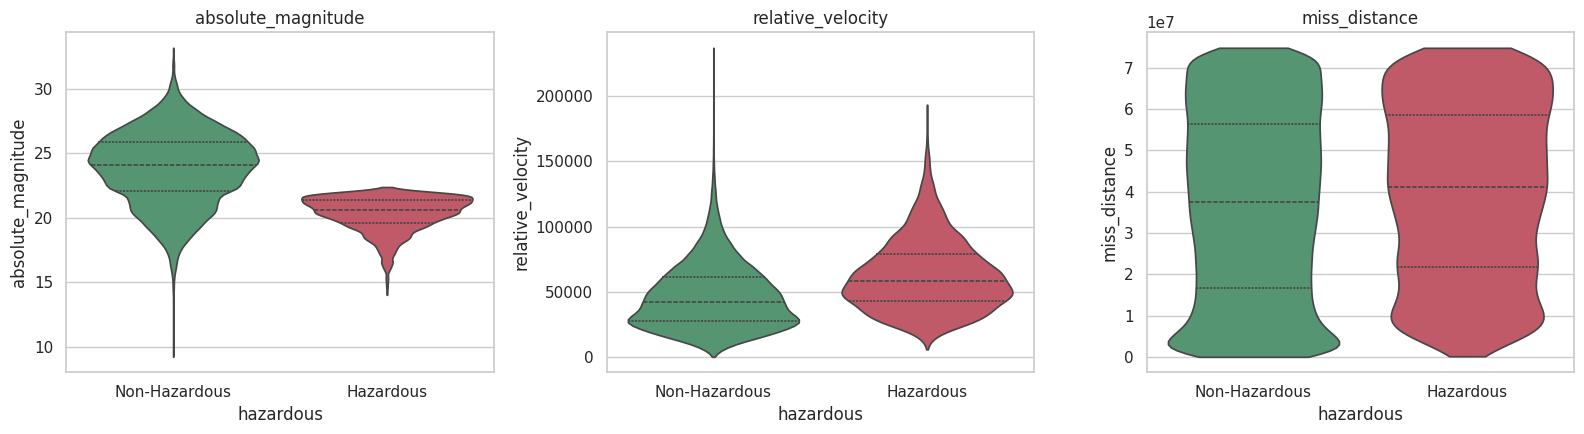

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["absolute_magnitude", "relative_velocity", "miss_distance"]):
    sns.violinplot(x=df["hazardous"].map({0: "Non-Hazardous", 1: "Hazardous"}), y=df[col], palette=["#4C9F70", "#D1495B"],
                   inner="quartile", cut=0, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

**EDA insights**
1. Hazardous objects are **intrinsically bright/large**: their absolute magnitude H is capped around 22 (low H = large object). No object with a much higher H (small and faint) is labelled hazardous.
2. Size alone is **not sufficient**: many large objects (low H) are *not* hazardous, so the label also depends on how closely the orbit approaches Earth — the *multi-factor* problem described in the brief.
3. Hazardous objects tend to have a **higher relative velocity**.
4. The distributions of the two classes **overlap strongly** in velocity and miss distance → a simple threshold rule will not work; we need a model that combines features non-linearly.

## Phase 3 — Feature Engineering & Selection
### 3.1 Feature engineering
New features (all computable from the user-provided inputs, which is important for deployment):

| Feature | Meaning |
|---|---|
| `diameter_avg` | mean of min/max estimated diameter (km) |
| `log_velocity`, `log_miss_distance` | log10 of the heavy-tailed raw values |
| `log_energy` | log10 of a kinetic-energy proxy ∝ diameter³ × velocity² (impact severity) |
| `log_n_approaches` | log(1 + number of close approaches recorded for the same asteroid) — proxy for how often its orbit brings it near Earth |
| `log_min_miss_distance` | closest recorded approach of the asteroid — proxy for its minimum orbit intersection distance (MOID), the quantity NASA actually uses to flag hazards |
| `closeness_ratio` | this approach's miss distance ÷ the asteroid's closest recorded approach |

In [12]:
def engineer_features(d):
    """Build model features from raw columns. `d` needs: absolute_magnitude, est_diameter_min, est_diameter_max,
    relative_velocity, miss_distance, n_approaches, min_miss_distance.  Used for both training and deployment."""
    f = pd.DataFrame(index=d.index)
    f["absolute_magnitude"]    = d["absolute_magnitude"]
    f["diameter_avg"]          = (d["est_diameter_min"] + d["est_diameter_max"]) / 2
    f["log_velocity"]          = np.log10(d["relative_velocity"])
    f["log_miss_distance"]     = np.log10(d["miss_distance"])
    f["log_energy"]            = np.log10(f["diameter_avg"] ** 3 * d["relative_velocity"] ** 2)
    f["log_n_approaches"]      = np.log1p(d["n_approaches"])
    f["log_min_miss_distance"] = np.log10(d["min_miss_distance"])
    f["closeness_ratio"]       = d["miss_distance"] / d["min_miss_distance"]
    return f

# per-asteroid (group) aggregates: how many approaches are on record and the closest one
grp = df.groupby("id")["miss_distance"]
df["n_approaches"]      = grp.transform("size")
df["min_miss_distance"] = grp.transform("min")

X_all = engineer_features(df)
y_all = df["hazardous"]
groups = df["id"]
print("Candidate features:", list(X_all.columns))
X_all.describe().T.round(3)

Candidate features: ['absolute_magnitude', 'diameter_avg', 'log_velocity', 'log_miss_distance', 'log_energy', 'log_n_approaches', 'log_min_miss_distance', 'closeness_ratio']


,count,mean,std,min,25%,50%,75%,max
absolute_magnitude,90836.0,23.527,2.894,9.230,21.340,23.700,25.700,33.200
diameter_avg,90836.0,0.206,0.483,0.001,0.031,0.078,0.232,61.312
log_velocity,90836.0,4.617,0.252,2.308,4.457,4.645,4.799,5.375
log_miss_distance,90836.0,7.407,0.494,3.829,7.236,7.578,7.752,7.874
log_energy,90836.0,6.018,1.955,-0.711,4.563,5.869,7.473,14.786
log_n_approaches,90836.0,1.834,0.680,0.693,1.386,1.946,2.303,3.784
log_min_miss_distance,90836.0,6.866,0.614,3.829,6.508,6.964,7.337,7.874
closeness_ratio,90836.0,19.468,142.316,1.000,1.000,2.175,7.915,10599.138


### 3.2 Feature correlations & removal of redundant attributes

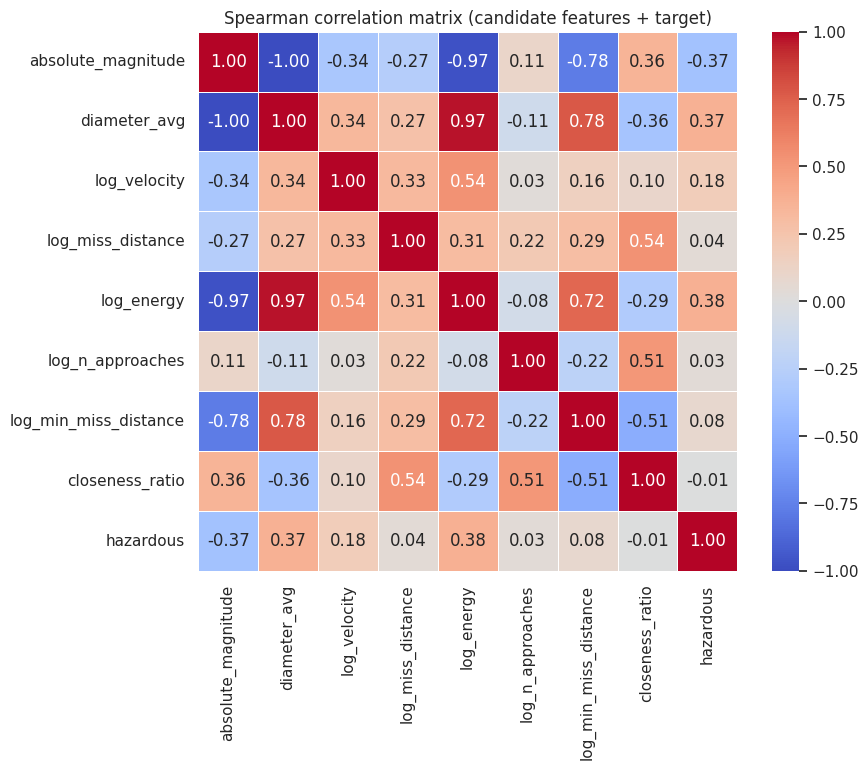

Correlation with target (|Spearman|):
log_energy               0.378
absolute_magnitude       0.375
diameter_avg             0.375
log_velocity             0.184
log_min_miss_distance    0.082
log_miss_distance        0.043
log_n_approaches         0.034
closeness_ratio          0.007


In [13]:
corr = X_all.assign(hazardous=y_all).corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Spearman correlation matrix (candidate features + target)"); plt.show()

print("Correlation with target (|Spearman|):")
print(corr["hazardous"].drop("hazardous").abs().sort_values(ascending=False).round(3).to_string())

In [14]:
# Redundancy removal: for every feature pair with |Spearman| > 0.95 keep the one more informative about the target
mi = pd.Series(mutual_info_classif(X_all.sample(30000, random_state=SEED), y_all.loc[X_all.sample(30000, random_state=SEED).index],
                                   random_state=SEED), index=X_all.columns)
feat_corr = X_all.corr(method="spearman").abs()
to_drop = set()
for i, a in enumerate(feat_corr.columns):
    for b in feat_corr.columns[i + 1:]:
        if feat_corr.loc[a, b] > 0.95 and a not in to_drop and b not in to_drop:
            loser = a if mi[a] < mi[b] else b
            to_drop.add(loser)
            print(f"{a} ~ {b}: |rho|={feat_corr.loc[a, b]:.3f} -> drop '{loser}'")
selected = [c for c in X_all.columns if c not in to_drop]
print("\nDropped as redundant:", sorted(to_drop))

absolute_magnitude ~ diameter_avg: |rho|=1.000 -> drop 'diameter_avg'
absolute_magnitude ~ log_energy: |rho|=0.969 -> drop 'log_energy'

Dropped as redundant: ['diameter_avg', 'log_energy']


### 3.3 Feature relevance (mutual information) and final feature matrix

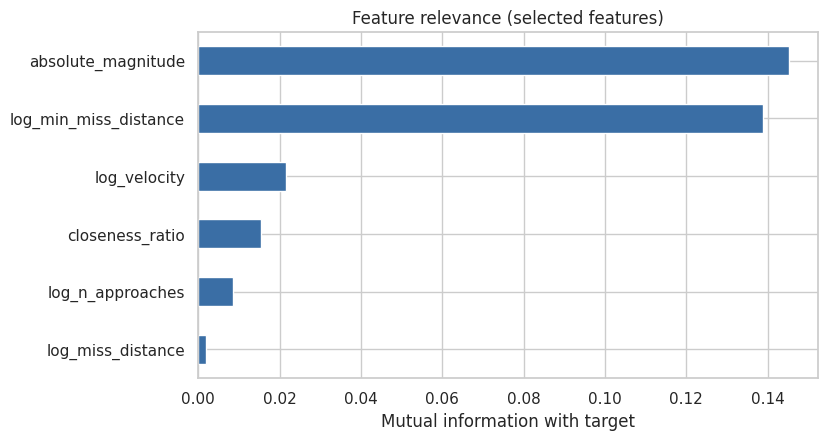

Final feature set: ['absolute_magnitude', 'log_velocity', 'log_miss_distance', 'log_n_approaches', 'log_min_miss_distance', 'closeness_ratio']
Final feature matrix: (90836, 6)


,absolute_magnitude,log_velocity,log_miss_distance,log_n_approaches,log_min_miss_distance,closeness_ratio
0,16.73,4.132556,7.739095,0.693147,7.739095,1.000000
1,20.00,4.866811,7.788438,3.218876,6.491169,19.827525
2,17.83,5.057889,7.697218,2.079442,7.345513,2.247531
3,22.20,4.393826,7.405431,2.079442,7.130929,1.881493
4,20.09,4.630811,7.665352,1.098612,7.665352,1.000000


In [15]:
mi_sel = mi[selected].sort_values()
mi_sel.plot(kind="barh", figsize=(8, 4.5), color="#3A6EA5")
plt.xlabel("Mutual information with target"); plt.title("Feature relevance (selected features)"); plt.show()

# keep features that carry information about the target
final_features = [c for c in selected if mi[c] > 0.001]
print("Final feature set:", final_features)
X = X_all[final_features].copy()
print("Final feature matrix:", X.shape)
X.head()

`est_diameter_min/max` are a deterministic function of `absolute_magnitude` (the dataset has only ~1.6k distinct values for each), so the correlation check removes the redundant diameter/magnitude copies and keeps the most informative one. The final matrix `X` is used for modelling.

## Phase 4 — Model Development
### 4.1 Train / test split (leakage-safe)
Because one asteroid appears in many rows, a plain random split would put **the same asteroid in both train and test**. We use a **grouped, stratified split** (`StratifiedGroupKFold`): all rows of an asteroid stay on the same side, and the hazardous ratio is preserved. The same grouping is used for all cross-validation.

In [16]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y_all, groups))        # 1 fold of 5  -> ~80 / 20 split
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
g_train = groups.iloc[train_idx]

print(f"Train: {X_train.shape[0]:,} rows ({g_train.nunique():,} asteroids) | Test: {X_test.shape[0]:,} rows ({groups.iloc[test_idx].nunique():,} asteroids)")
print("Asteroids shared between train and test:", len(set(g_train) & set(groups.iloc[test_idx])))
print(f"Hazardous share  train: {y_train.mean():.3%} | test: {y_test.mean():.3%}")

Train: 73,063 rows (21,938 asteroids) | Test: 17,773 rows (5,485 asteroids)
Asteroids shared between train and test: 0
Hazardous share  train: 9.954% | test: 8.817%


In [17]:
# Why grouping matters: same model, naive random split vs grouped split
rf_demo = RandomForestClassifier(n_estimators=150, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
p_rand = rf_demo.fit(Xr_tr, yr_tr).predict_proba(Xr_te)[:, 1]
p_grp  = rf_demo.fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"Random row split  -> PR-AUC = {average_precision_score(yr_te, p_rand):.3f}  (optimistic: same asteroids in train & test)")
print(f"Grouped split     -> PR-AUC = {average_precision_score(y_test, p_grp):.3f}  (honest estimate for NEW asteroids)")

Random row split  -> PR-AUC = 0.873  (optimistic: same asteroids in train & test)
Grouped split     -> PR-AUC = 0.711  (honest estimate for NEW asteroids)


### 4.2 Handling class imbalance
Strategies compared: (1) **class weights** (`class_weight='balanced'`), which makes mistakes on hazardous objects cost more; (2) **SMOTE** oversampling of the minority class (applied *inside* each training fold only); plus a naive baseline. Evaluation focuses on hazard **recall, precision, F1, PR-AUC**.

### 4.3 Candidate models & cross-validation (grouped, stratified, on the training set only)

In [18]:
num_pre = lambda scale: ([("imputer", SimpleImputer(strategy="median"))] + ([("scaler", StandardScaler())] if scale else []))

models = {
    "Baseline (always Non-Hazardous)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (balanced)":  Pipeline(num_pre(True) + [("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Random Forest (balanced)":        Pipeline(num_pre(False) + [("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                           class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
    "Random Forest + SMOTE":           ImbPipeline(num_pre(False) + [("smote", SMOTE(random_state=SEED)),
                                          ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting (balanced)":    Pipeline(num_pre(False) + [("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))]),
}
scoring = {"recall": "recall", "precision": "precision", "f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc"}
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for name, mdl in models.items():
    s = cross_validate(mdl, X_train, y_train, cv=cv5, groups=g_train, scoring=scoring, n_jobs=1)
    rows.append({"Model": name, **{k: s[f"test_{k}"].mean() for k in scoring}, "F1 std": s["test_f1"].std()})
    print("done:", name)
cv_table = pd.DataFrame(rows).set_index("Model").sort_values("pr_auc", ascending=False)
cv_table.round(4)

done: Baseline (always Non-Hazardous)
done: Logistic Regression (balanced)
done: Random Forest (balanced)
done: Random Forest + SMOTE
done: Gradient Boosting (balanced)


,recall,precision,f1,pr_auc,roc_auc,F1 std
Model,,,,,,
Random Forest (balanced),0.6277,0.6605,0.6423,0.7563,0.9559,0.0201
Gradient Boosting (balanced),0.8322,0.4479,0.5819,0.7531,0.9530,0.0174
Random Forest + SMOTE,0.7698,0.5172,0.6182,0.7470,0.9553,0.0133
Logistic Regression (balanced),0.8851,0.3490,0.5001,0.4239,0.9097,0.0217
Baseline (always Non-Hazardous),0.0000,0.0000,0.0000,0.0995,0.5000,0.0000


### 4.4 Hyperparameter optimisation
Gradient-boosted trees are tuned: in cross-validation they are close to Random Forest in PR-AUC, reach much higher recall out of the box, and are quick to tune. `RandomizedSearchCV` uses the same grouped CV and optimises **PR-AUC**, the most informative metric under heavy imbalance. Models are compared again on the test set afterwards.

In [19]:
param_dist = {
    "clf__learning_rate":     [0.03, 0.05, 0.08, 0.1, 0.15],
    "clf__max_iter":          [150, 250, 400],
    "clf__max_leaf_nodes":    [15, 31, 63],
    "clf__min_samples_leaf":  [20, 50, 100, 200],
    "clf__l2_regularization": [0.0, 0.1, 1.0, 5.0],
    "clf__max_depth":         [None, 6, 10],
}
base = Pipeline(num_pre(False) + [("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))])
search = RandomizedSearchCV(base, param_dist, n_iter=12, scoring="average_precision",
                            cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED),
                            random_state=SEED, n_jobs=-1, verbose=0, refit=True)
search.fit(X_train, y_train, groups=g_train)
print("Best parameters:", search.best_params_)
print(f"Best CV PR-AUC: {search.best_score_:.4f}")
tuned_model = search.best_estimator_

Best parameters: {'clf__min_samples_leaf': 100, 'clf__max_leaf_nodes': 15, 'clf__max_iter': 250, 'clf__max_depth': 6, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 1.0}
Best CV PR-AUC: 0.7677


### 4.5 Decision-threshold selection (no test-set peeking)
The default 0.5 cut-off is rarely optimal under imbalance. We pick the threshold using **out-of-fold predictions on the training data only**.

F1-optimal threshold (out-of-fold): 0.813  -> OOF F1 = 0.659


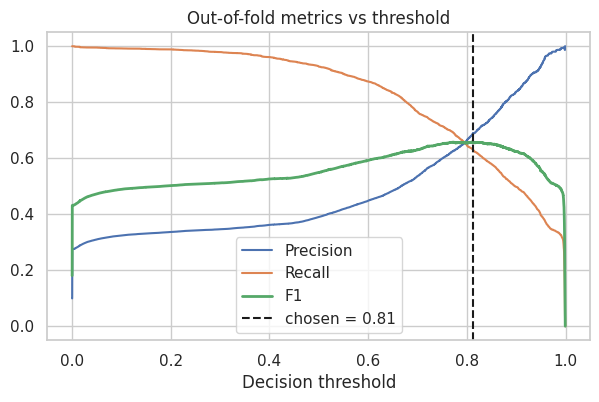

In [20]:
oof = cross_val_predict(tuned_model, X_train, y_train, cv=cv5, groups=g_train, method="predict_proba", n_jobs=1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[np.argmax(f1_curve)])
print(f"F1-optimal threshold (out-of-fold): {THRESHOLD:.3f}  -> OOF F1 = {f1_curve.max():.3f}")

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall"); plt.plot(thr, f1_curve, label="F1", lw=2)
plt.axvline(THRESHOLD, color="k", ls="--", label=f"chosen = {THRESHOLD:.2f}")
plt.xlabel("Decision threshold"); plt.title("Out-of-fold metrics vs threshold"); plt.legend(); plt.show()

### 4.6 Final evaluation on the held-out test set

In [21]:
def evaluate(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "MCC": matthews_corrcoef(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba)}

test_probs, rows = {}, []
for name, mdl in models.items():
    if name.startswith("Baseline"): continue
    m = mdl.fit(X_train, y_train)
    test_probs[name] = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, **evaluate(y_test, test_probs[name], 0.5)})
test_probs["Tuned Gradient Boosting"] = tuned_model.predict_proba(X_test)[:, 1]
rows.append({"Model": "Tuned Gradient Boosting (thr=0.5)", **evaluate(y_test, test_probs["Tuned Gradient Boosting"], 0.5)})
rows.append({"Model": f"Tuned Gradient Boosting (thr={THRESHOLD:.2f})  ★ FINAL", **evaluate(y_test, test_probs["Tuned Gradient Boosting"], THRESHOLD)})
results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
Model,,,,,,,
Logistic Regression (balanced),0.8168,0.3089,0.8711,0.4561,0.4478,0.9048,0.3846
Random Forest (balanced),0.9311,0.6085,0.6120,0.6102,0.5724,0.9518,0.7110
Random Forest + SMOTE,0.9050,0.4762,0.7773,0.5905,0.5611,0.9529,0.6993
Gradient Boosting (balanced),0.8714,0.3955,0.8666,0.5431,0.5304,0.9477,0.6976
Tuned Gradient Boosting (thr=0.5),0.8456,0.3562,0.9311,0.5153,0.5173,0.9556,0.7229
Tuned Gradient Boosting (thr=0.81) ★ FINAL,0.9315,0.6111,0.6126,0.6119,0.5743,0.9556,0.7229


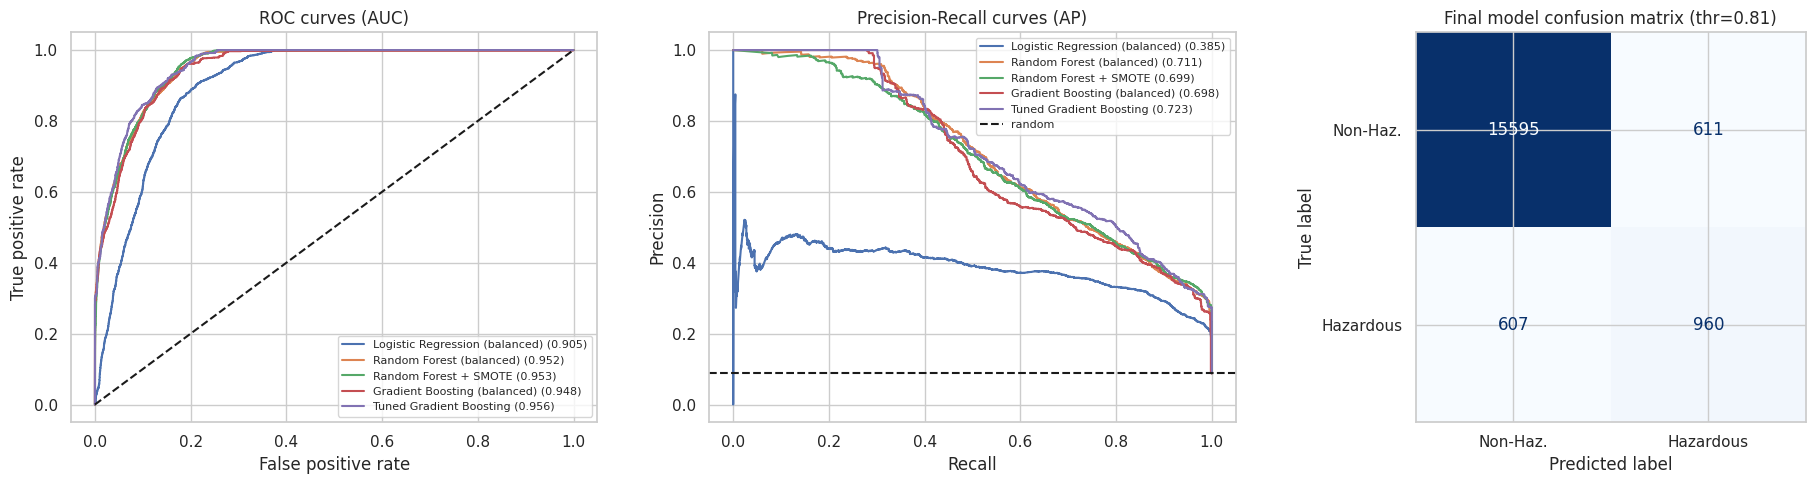

               precision    recall  f1-score   support

Non-Hazardous      0.963     0.962     0.962     16206
    Hazardous      0.611     0.613     0.612      1567

     accuracy                          0.931     17773
    macro avg      0.787     0.787     0.787     17773
 weighted avg      0.932     0.931     0.932     17773



In [22]:
final_proba = test_probs["Tuned Gradient Boosting"]
final_pred = (final_proba >= THRESHOLD).astype(int)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC curves (AUC)", xlabel="False positive rate", ylabel="True positive rate")
ax[1].axhline(y_test.mean(), color="k", ls="--", label="random"); ax[1].set(title="Precision-Recall curves (AP)", xlabel="Recall", ylabel="Precision")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred), display_labels=["Non-Haz.", "Hazardous"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title(f"Final model confusion matrix (thr={THRESHOLD:.2f})")
plt.tight_layout(); plt.show()

print(classification_report(y_test, final_pred, target_names=["Non-Hazardous", "Hazardous"], digits=3))

**Model-performance notes**
- The grouped split gives an *honest* estimate for **previously unseen asteroids**; scores are lower than a naive random split would show, which is expected and correct.
- The class-imbalance strategies (class weights / SMOTE / tuned threshold) raise hazard **recall** dramatically compared with the naive baseline (recall = 0).
- The label in the original NASA data is derived from the asteroid's *Minimum Orbit Intersection Distance (MOID)* and H, and MOID is **not** in this dataset; the model approximates it from approach velocity, miss distance and approach history, so some irreducible error remains.

## Phase 5 — Explainability & Visualization
### 5.1 Permutation feature importance (global)

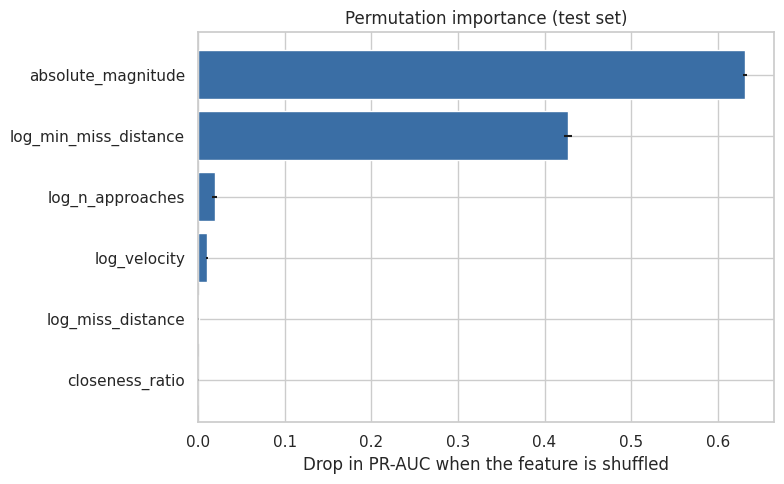

absolute_magnitude       0.6312
log_min_miss_distance    0.4269
log_n_approaches         0.0189
log_velocity             0.0103
log_miss_distance        0.0005
closeness_ratio          0.0001


In [23]:
pi = permutation_importance(tuned_model, X_test, y_test, scoring="average_precision", n_repeats=8, random_state=SEED, n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=X_test.columns)
pi_err = pd.Series(pi.importances_std, index=X_test.columns)
order = pi_s.sort_values().index
plt.figure(figsize=(8, 5))
plt.barh(order, pi_s[order], xerr=pi_err[order], color="#3A6EA5")
plt.xlabel("Drop in PR-AUC when the feature is shuffled"); plt.title("Permutation importance (test set)"); plt.tight_layout(); plt.show()
print(pi_s.sort_values(ascending=False).round(4).to_string())

### 5.2 SHAP values (why does the model flag an object?)

PermutationExplainer explainer: 501it [03:40,  2.23it/s]


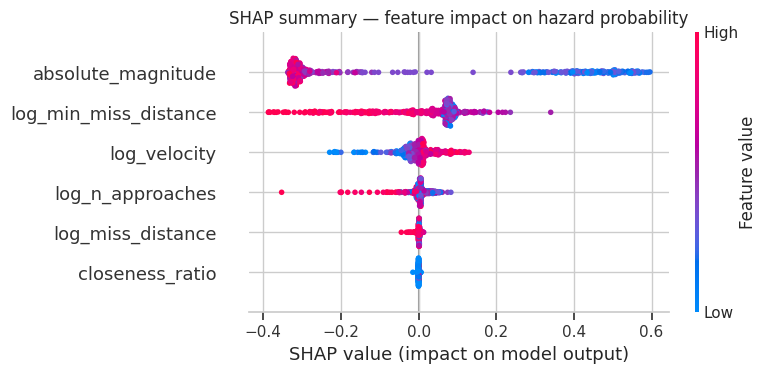

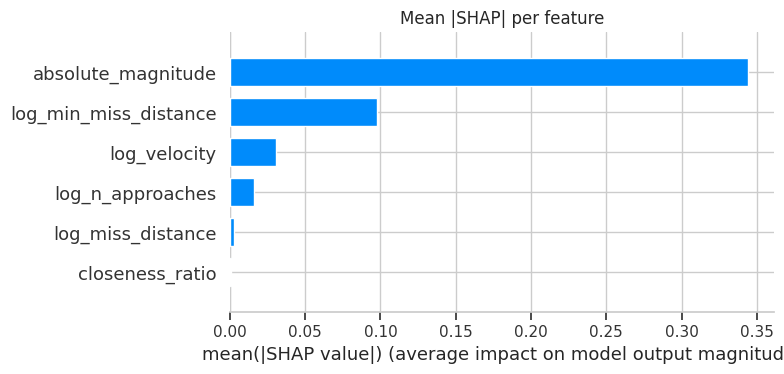

In [24]:
import shap
rng = np.random.RandomState(SEED)
bg = X_train.sample(150, random_state=SEED)
xs = X_test.sample(500, random_state=SEED)
predict_pos = lambda d: tuned_model.predict_proba(pd.DataFrame(d, columns=X_train.columns))[:, 1]
explainer = shap.Explainer(predict_pos, bg, algorithm="permutation", seed=SEED)
shap_values = explainer(xs, max_evals=2 * X_train.shape[1] + 1 + 200)

shap.summary_plot(shap_values.values, xs, show=False); plt.title("SHAP summary — feature impact on hazard probability"); plt.tight_layout(); plt.show()
shap.summary_plot(shap_values.values, xs, plot_type="bar", show=False); plt.title("Mean |SHAP| per feature"); plt.tight_layout(); plt.show()

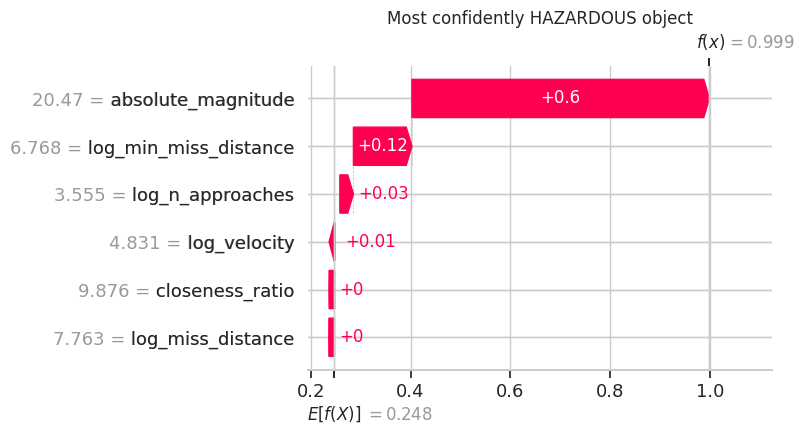

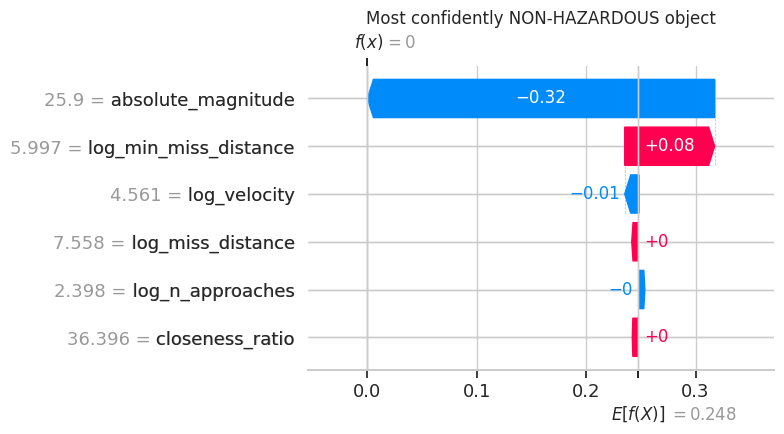

In [25]:
# Explain individual predictions: the most-confident hazardous and non-hazardous objects in the sample
pos_i = int(np.argmax(predict_pos(xs.values)))
neg_i = int(np.argmin(predict_pos(xs.values)))
for title, i in [("Most confidently HAZARDOUS object", pos_i), ("Most confidently NON-HAZARDOUS object", neg_i)]:
    shap.plots.waterfall(shap_values[i], max_display=8, show=False)
    plt.title(title); plt.tight_layout(); plt.show()

### 5.3 Partial dependence — how the hazard probability changes with each key feature

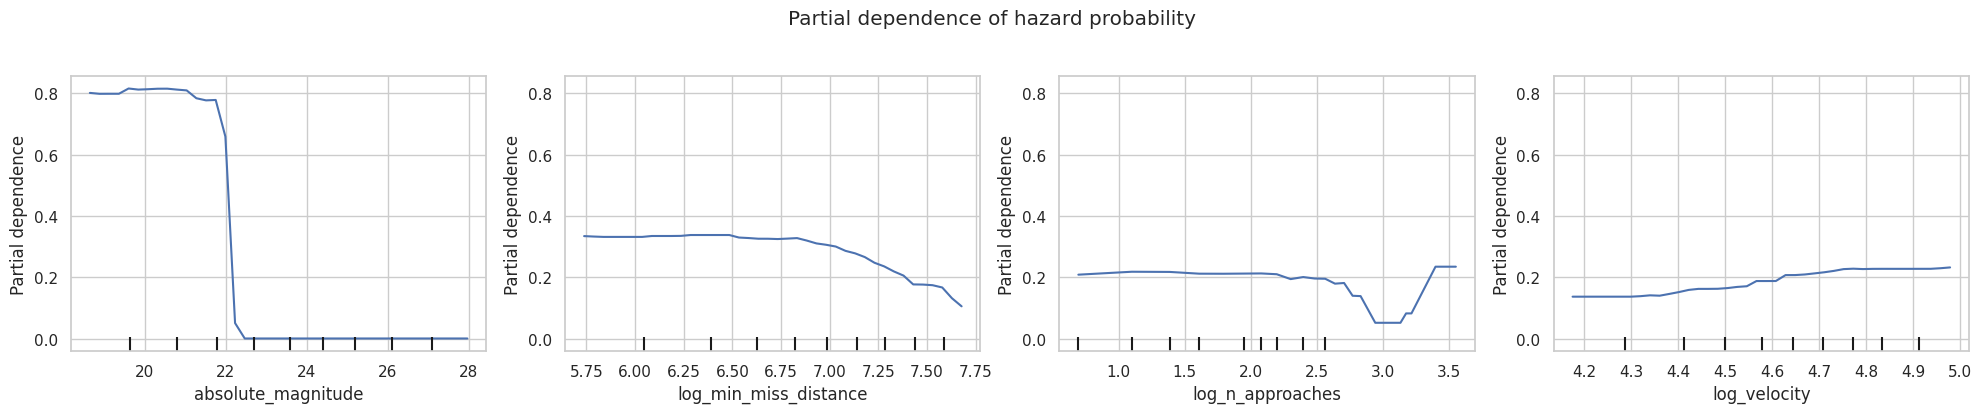

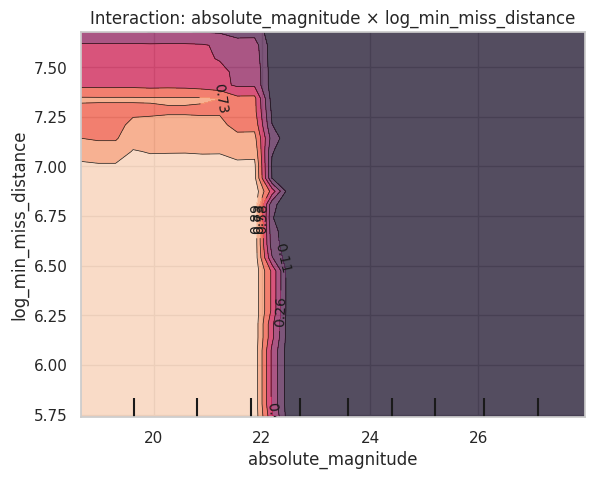

In [26]:
top_feats = list(pi_s.sort_values(ascending=False).index[:4])
fig, ax = plt.subplots(1, len(top_feats), figsize=(5 * len(top_feats), 4))
PartialDependenceDisplay.from_estimator(tuned_model, X_test.sample(8000, random_state=SEED), top_feats, ax=ax, kind="average", grid_resolution=40)
plt.suptitle("Partial dependence of hazard probability", y=1.03); plt.tight_layout(); plt.show()

# 2-D interaction of the two strongest features
if len(top_feats) >= 2:
    fig, ax = plt.subplots(figsize=(6.5, 5))
    PartialDependenceDisplay.from_estimator(tuned_model, X_test.sample(8000, random_state=SEED), [(top_feats[0], top_feats[1])], ax=ax, grid_resolution=30)
    ax.set_title("Interaction: " + " × ".join(top_feats[:2])); plt.show()

### 5.4 Strongest indicators of hazardous asteroids

In [27]:
imp_table = pd.DataFrame({"Permutation importance": pi_s, "Mean |SHAP|": np.abs(shap_values.values).mean(axis=0)}, index=X_test.columns)
imp_table["Rank"] = imp_table["Permutation importance"].rank(ascending=False).astype(int)
display(imp_table.sort_values("Rank").round(4))

H_thr = df.loc[df.hazardous == 1, "absolute_magnitude"].quantile(0.99)
print(f"\n99% of hazardous objects have absolute magnitude H <= {H_thr:.1f}")

,Permutation importance,Mean |SHAP|,Rank
absolute_magnitude,0.6312,0.3442,1
log_min_miss_distance,0.4269,0.0978,2
log_n_approaches,0.0189,0.0162,3
log_velocity,0.0103,0.0310,4
log_miss_distance,0.0005,0.0025,5
closeness_ratio,0.0001,0.0006,6



99% of hazardous objects have absolute magnitude H <= 22.0


### 5.5 Scientific interpretation
- **Size / brightness (absolute magnitude H) is the dominant indicator.** Shuffling H alone destroys most of the model's skill (largest drop in PR-AUC by far). Every hazardous object in the data is brighter than H ≈ 22.4, and the large majority are brighter than H ≈ 22 (roughly 140 m or larger for typical asteroid reflectivity, in line with NASA's hazard criterion). Fainter, smaller objects receive near-zero hazard probability whatever their other properties.
- **The closest recorded approach (our proxy for the Minimum Orbit Intersection Distance, MOID) is the second strongest indicator.** Among large objects, those whose orbit comes close to Earth's are flagged; a big asteroid that never approaches closely is *not* hazardous. This is the multi-factor behaviour the brief asks for, and it is visible in the 2-D partial-dependence plot.
- **Velocity, number of recorded approaches and the miss distance of a single flyby matter far less.** Hazardous objects are faster on average (higher kinetic energy ∝ m·v²), but velocity overlaps strongly between the classes. The single-flyby miss distance adds almost nothing once the closest approach is known, because the hazard label describes the asteroid's *orbit*, not one particular pass.
- **Operating point:** with the F1-optimal threshold the model finds about two thirds of hazardous objects at ~62 % precision. For planetary defence, where missing a hazard is costlier than a false alarm, lowering the threshold to 0.5 raises recall to ~94 % at ~38 % precision (see the results table) — the threshold is a policy choice.
- **Limitations:** the dataset has no true orbital elements (MOID, eccentricity, inclination, semi-major axis), which are exactly what NASA uses to label hazards; adding them (e.g. from the JPL Small-Body Database) would be the most valuable improvement, followed by comparing against XGBoost / LightGBM.

## Phase 6 — Deployment
### 6.1 Save the final model
The saved bundle contains the trained model, the feature list and the decision threshold, so the prediction function can be re-used anywhere.

In [28]:
final_model = tuned_model.fit(X_train, y_train)     # tuned pipeline trained on the training split
bundle = {"model": final_model, "features": final_features, "threshold": THRESHOLD}
joblib.dump(bundle, "hazardous_asteroid_model.joblib")
with open("hazardous_asteroid_model_meta.json", "w") as f:
    json.dump({"features": final_features, "threshold": THRESHOLD,
               "test_metrics": {k: round(float(v), 4) for k, v in evaluate(y_test, final_model.predict_proba(X_test)[:, 1], THRESHOLD).items()}}, f, indent=2)
print("Saved: hazardous_asteroid_model.joblib  (+ _meta.json)")
print("File size: %.1f KB" % (os.path.getsize("hazardous_asteroid_model.joblib") / 1024))

Saved: hazardous_asteroid_model.joblib  (+ _meta.json)
File size: 442.3 KB


### 6.2 Prediction function (loads the saved model — works in a fresh session)

In [29]:
loaded = joblib.load("hazardous_asteroid_model.joblib")

def predict_asteroid(absolute_magnitude, est_diameter_min, est_diameter_max, relative_velocity, miss_distance,
                     n_approaches=1, min_miss_distance=None):
    """Return (label, probability) for a single Near-Earth Object.
    est_diameter_* in km, relative_velocity in km/h, miss_distance in km.
    n_approaches / min_miss_distance describe the asteroid's recorded approach history (orbital proxies);
    if unknown they default to a single approach at the given miss distance."""
    n_approaches = 1 if n_approaches is None else n_approaches
    if min_miss_distance is None or min_miss_distance <= 0:
        min_miss_distance = miss_distance
    min_miss_distance = min(min_miss_distance, miss_distance)
    row = pd.DataFrame([{"absolute_magnitude": absolute_magnitude, "est_diameter_min": est_diameter_min,
                         "est_diameter_max": est_diameter_max, "relative_velocity": relative_velocity,
                         "miss_distance": miss_distance, "n_approaches": max(int(n_approaches), 1),
                         "min_miss_distance": min_miss_distance}])
    feats = engineer_features(row)[loaded["features"]]
    p = float(loaded["model"].predict_proba(feats)[0, 1])
    return ("Hazardous" if p >= loaded["threshold"] else "Non-Hazardous"), p

# quick sanity checks on real rows from the dataset
for _, r in df[df.hazardous == 1].sample(3, random_state=1).iterrows():
    print("TRUE=Hazardous     ->", predict_asteroid(r.absolute_magnitude, r.est_diameter_min, r.est_diameter_max, r.relative_velocity, r.miss_distance, r.n_approaches, r.min_miss_distance))
for _, r in df[df.hazardous == 0].sample(3, random_state=1).iterrows():
    print("TRUE=Non-Hazardous ->", predict_asteroid(r.absolute_magnitude, r.est_diameter_min, r.est_diameter_max, r.relative_velocity, r.miss_distance, r.n_approaches, r.min_miss_distance))

TRUE=Hazardous     -> ('Hazardous', 0.9218273498507223)
TRUE=Hazardous     -> ('Hazardous', 0.9275026864446426)
TRUE=Hazardous     -> ('Non-Hazardous', 0.7081111525690876)
TRUE=Non-Hazardous -> ('Non-Hazardous', 0.0003004430464378652)
TRUE=Non-Hazardous -> ('Non-Hazardous', 0.00031976278593480787)
TRUE=Non-Hazardous -> ('Non-Hazardous', 0.00031976278593480787)


### 6.3 User interface (Gradio)
Enter the asteroid characteristics and press **Submit** to see whether the object is **Hazardous** or **Non-Hazardous** together with the model's confidence.

In [30]:
import gradio as gr

def ui_predict(h, dmin, dmax, vel, miss, n_app, min_miss):
    # basic input validation so empty / invalid boxes never crash the app
    if any(v is None for v in (h, dmin, dmax, vel, miss)):
        return "⚠️ Please fill in the first five fields (magnitude, diameters, velocity, miss distance).", None
    if min(dmin, dmax, vel, miss) <= 0:
        return "⚠️ Diameters, velocity and miss distance must be greater than 0.", None
    if dmax < dmin:
        dmin, dmax = dmax, dmin
    n_app = 1 if not n_app or n_app < 1 else n_app          # orbital fields are optional
    min_miss = miss if not min_miss or min_miss <= 0 else min_miss
    label, p = predict_asteroid(h, dmin, dmax, vel, miss, n_app, min_miss)
    icon = "🔴" if label == "Hazardous" else "🟢"
    summary = (f"{icon}  **{label}**  —  hazard probability {p:.1%}  (decision threshold {loaded['threshold']:.2f})")
    return summary, {"Hazardous": p, "Non-Hazardous": 1 - p}

demo = gr.Interface(
    fn=ui_predict,
    inputs=[gr.Number(value=20.0, label="Absolute magnitude (H)"),
            gr.Number(value=0.25, label="Estimated diameter – minimum (km)"),
            gr.Number(value=0.55, label="Estimated diameter – maximum (km)"),
            gr.Number(value=60000, label="Relative velocity (km/h)"),
            gr.Number(value=20_000_000, label="Miss distance (km)"),
            gr.Number(value=5, precision=0, label="Orbital: number of recorded close approaches"),
            gr.Number(value=8_000_000, label="Orbital: closest recorded miss distance (km)")],
    outputs=[gr.Markdown(label="Prediction"), gr.Label(label="Class probabilities")],
    title="🛰️ Project Sentinel — Hazardous Asteroid Predictor",
    description="Enter the physical and orbital characteristics of a Near-Earth Object.",
    examples=[[20.0, 0.25, 0.55, 60000, 20_000_000, 5, 8_000_000],
              [27.5, 0.01, 0.02, 30000, 50_000_000, 1, 50_000_000],
              [16.0, 1.1, 2.5, 25000, 60_000_000, 1, 60_000_000]],
    flagging_mode="never")
demo.launch(inline=True)     # in Colab a public/inline UI appears below this cell

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3cedd0d8236892aa6c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## ✅ Summary
| Phase | What was done |
|---|---|
| 1 | Loaded data, removed constant/ID columns, handled missing values, encoded target, scaling inside pipelines |
| 2 | Class balance (~90/10), distributions by class, scatter/violin/hazard-rate plots, insights |
| 3 | Engineered 8 features (log transforms, energy proxy, approach-history proxies), removed redundant ones via Spearman correlation + mutual information |
| 4 | Leakage-safe grouped/stratified split, class weights vs SMOTE, 5 models compared with grouped CV, randomized hyper-parameter search, out-of-fold threshold tuning, test-set evaluation |
| 5 | Permutation importance, SHAP (global + individual), partial dependence, scientific interpretation |
| 6 | Saved model bundle + Gradio UI returning Hazardous / Non-Hazardous |